# Project 16: Advanced CNN Architectures with Residual Blocks

This project demonstrates modern deep learning primitives in NeuroGebra:
- `Conv2D`: 2D spatial feature convolutions
- `LayerNorm`: Feature-wise normalization
- `ResidualDense`: Skip-connection residual block
- `GlobalAveragePooling2D`: Spatial downsampling into compact feature representation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.builders.model_builder import ModelBuilder
from neurogebra.datasets import Datasets

np.random.seed(42)
X_raw, y_raw = Datasets.load_digits(verbose=False)
# Shape into 8x8 image representations
X_img = (X_raw[:600] / 16.0).reshape(-1, 8, 8, 1)
y_oh = np.eye(10)[y_raw[:600]]
print(f'[INFO] Input image tensor shape: {X_img.shape}')


[INFO] Input image tensor shape: (600, 8, 8, 1)


In [2]:
# Construct Mini-ResNet Architecture with NeuroGebra
builder = ModelBuilder()
model = builder.Sequential([
    builder.Conv2D(filters=16, kernel_size=3, padding='same', activation='relu'),
    builder.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'),
    builder.GlobalAveragePooling2D(),
    builder.LayerNorm(),
    builder.ResidualDense(units=32, activation='relu'),
    builder.Dense(10, activation='softmax'),
], name='Mini_ResNet')

model.compile(loss='categorical_crossentropy', optimizer='adam', learning_rate=0.005)
model.summary(educational=False)



Compiling model...
   Loss: categorical_crossentropy
   Optimizer: adam (lr=0.005)
   Metrics: accuracy
   Model compiled successfully.


  Model: Mini_ResNet

  Layer 1: Layer(conv2d, units=16, activation=relu, kernel_size=3, padding=same)

  Layer 2: Layer(conv2d, units=32, activation=relu, kernel_size=3, padding=same)

  Layer 3: Layer(global_avgpool2d)

  Layer 4: Layer(layernorm, eps=1e-05)

  Layer 5: Layer(residual_dense, units=32, activation=relu)

  Layer 6: Layer(dense, units=10, activation=softmax)
           Parameters: ~330

  Total Parameters: ~330




 Training Mini_ResNet...

   Training samples: 600
   Epochs: 8
   Batch size: 32


Execution plan:

1.  The model will see 480 training examples
    It learns patterns by adjusting its weights

2.  This process repeats 8 times (epochs)
    Each time, the model gets better at predictions

3.  After each epoch, we test on 120 validation examples
    This tells us if the model is learning or just memorizing

Let's begin.


  Epoch   1/8 ███░░░░░░░░░░░░░░░░░░░░░░░░░░░ loss: 3.0038 - acc: 0.1146 - val_loss: 2.3718 - val_acc: 0.1083 - 0.1s
  Epoch   2/8 ███████░░░░░░░░░░░░░░░░░░░░░░░ loss: 2.2828 - acc: 0.1333 - val_loss: 2.2585 - val_acc: 0.1167 - 0.1s
  Epoch   3/8 ███████████░░░░░░░░░░░░░░░░░░░ loss: 2.2052 - acc: 0.1750 - val_loss: 2.1934 - val_acc: 0.2417 - 0.1s
  Epoch   4/8 ███████████████░░░░░░░░░░░░░░░ loss: 2.1259 - acc: 0.2208 - val_loss: 2.0674 - val_acc: 0.3167 - 0.1s
  Epoch   5/8 ██████████████████░░░░░░░░░░░░ loss: 1.9290 - acc: 0.3042 - val_loss: 1.9089 - val_acc: 0.2750 -

<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


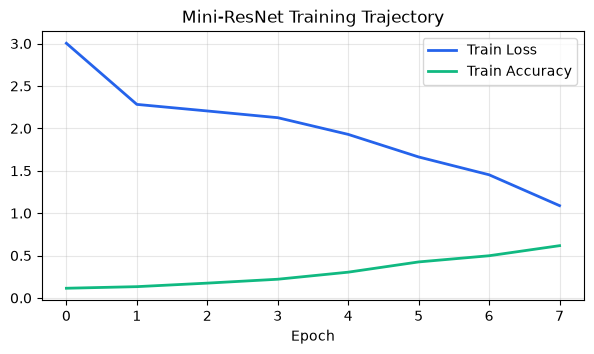

In [3]:
# Train residual network
history = model.fit(X_img, y_oh, epochs=8, batch_size=32, validation_split=0.2)
print(f'[SUCCESS] Training completed. Final Accuracy: {history["accuracy"][-1]*100:.2f}%')

plt.figure(figsize=(7, 3.5))
plt.plot(history['loss'], label='Train Loss', color='#2563eb', lw=2)
plt.plot(history['accuracy'], label='Train Accuracy', color='#10b981', lw=2)
plt.title('Mini-ResNet Training Trajectory')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
